# PRCP-1006 — Home Loan Default Risk Management

## Complete All-Dataset Implementation

This notebook is structured to satisfy the institute requirements in **one Jupyter notebook**:

1. Complete data analysis report.
2. Predictive modelling for home-loan default risk and risk/customer segments.
3. Model comparison report.
4. Production-model selection based on measured validation performance.
5. Challenges faced, techniques used, and reasons.
6. Business interpretation, limitations, conclusion, and future scope.

### Important change from the earlier notebook

The model now uses **all seven institute datasets**. The historical tables are not directly joined row-by-row. Instead, they are aggregated to the applicant level using `SK_ID_CURR` and then merged with `application_train.csv`.

This avoids duplicate applicant rows and reduces memory usage while preserving historical credit and repayment information.

**Required files in the same folder as this notebook:**
- `application_train.csv`
- `bureau.csv`
- `bureau_balance.csv`
- `POS_CASH_balance.csv`
- `credit_card_balance.csv`
- `previous_application.csv`
- `installments_payments.csv`


## 1. Project objective

The target variable is `TARGET`:

- `1` = Defaulter
- `0` = Non-Defaulter

`application_train.csv` is the base application table. The other six datasets contain previous-credit, previous-application, POS/cash, credit-card, bureau-balance, and installment-payment history.

The objective is to create applicant-level historical features and use them together with application information to model default risk.


In [1]:
# STEP 1: Environment setup and verification

from pathlib import Path
import gc
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)
from sklearn.base import clone

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")

PROJECT_DIR = Path.cwd()
CHUNK_SIZE = 200_000
RANDOM_STATE = 42

REQUIRED_FILES = [
    "application_train.csv",
    "bureau.csv",
    "bureau_balance.csv",
    "POS_CASH_balance.csv",
    "credit_card_balance.csv",
    "previous_application.csv",
    "installments_payments.csv"
]

print("Project directory:", PROJECT_DIR.resolve())
print("\nRequired dataset verification:")

missing_files = []
for name in REQUIRED_FILES:
    path = PROJECT_DIR / name
    if path.exists():
        print(f"✓ {name:<32} {path.stat().st_size / 1024**2:,.2f} MB")
    else:
        print(f"✗ {name:<32} NOT FOUND")
        missing_files.append(name)

if missing_files:
    raise FileNotFoundError(
        "The following required datasets are missing: " + ", ".join(missing_files)
    )

print("\nAll 7 institute datasets are available.")


Project directory: C:\Users\deepi\OneDrive\Projects ML\Home Loan Default - Risk management

Required dataset verification:
✓ application_train.csv            158.44 MB
✓ bureau.csv                       162.14 MB
✓ bureau_balance.csv               358.19 MB
✓ POS_CASH_balance.csv             374.51 MB
✓ credit_card_balance.csv          404.91 MB
✓ previous_application.csv         386.21 MB
✓ installments_payments.csv        689.62 MB

All 7 institute datasets are available.


In [2]:
# STEP 2: Inspect the seven datasets without loading all large files into memory

dataset_info = []

for name in REQUIRED_FILES:
    path = PROJECT_DIR / name
    header = pd.read_csv(path, nrows=0)
    dataset_info.append({
        "Dataset": name,
        "Columns": len(header.columns),
        "File Size (MB)": round(path.stat().st_size / 1024**2, 2),
        "Key Column Present": "SK_ID_CURR" in header.columns
    })

dataset_info = pd.DataFrame(dataset_info)
display(dataset_info)

# The application table is the target/base table.
app = pd.read_csv(PROJECT_DIR / "application_train.csv")
print("application_train shape:", app.shape)


,Dataset,Columns,File Size (MB),Key Column Present
0,application_train.csv,122,158.4400,True
1,bureau.csv,17,162.1400,True
2,bureau_balance.csv,3,358.1900,False
3,POS_CASH_balance.csv,8,374.5100,True
4,credit_card_balance.csv,23,404.9100,True
5,previous_application.csv,37,386.2100,True
6,installments_payments.csv,8,689.6200,True


application_train shape: (307511, 122)


## 2. Initial data quality and target analysis

The application table is analysed first because it contains the target. Historical datasets are then converted into applicant-level features before modelling.


In [3]:
# STEP 3: Data structure, duplicates, missing values and target distribution

print("Application dataset shape:", app.shape)
print("\nDuplicate rows:", app.duplicated().sum())
print("\nTarget distribution:")
display(app["TARGET"].value_counts().rename_axis("TARGET").reset_index(name="Count"))

target_rate = app["TARGET"].mean()
print(f"Overall default rate: {target_rate:.4%}")

missing_application = (
    app.isnull().mean()
    .sort_values(ascending=False)
    .head(20)
    .rename("Missing_Percentage")
    .to_frame()
)

print("\nTop 20 columns by missing percentage:")
display((missing_application * 100).round(2))


Application dataset shape: (307511, 122)

Duplicate rows: 0

Target distribution:


,TARGET,Count
0,0,282686
1,1,24825


Overall default rate: 8.0729%

Top 20 columns by missing percentage:


,Missing_Percentage
COMMONAREA_MEDI,69.8700
COMMONAREA_AVG,69.8700
COMMONAREA_MODE,69.8700
NONLIVINGAPARTMENTS_MODE,69.4300
NONLIVINGAPARTMENTS_AVG,69.4300
NONLIVINGAPARTMENTS_MEDI,69.4300
FONDKAPREMONT_MODE,68.3900
LIVINGAPARTMENTS_MODE,68.3500
LIVINGAPARTMENTS_AVG,68.3500
LIVINGAPARTMENTS_MEDI,68.3500


,count,mean,std,min,25%,50%,75%,max
AMT_INCOME_TOTAL,"307,511.0000","168,797.9193","237,123.1463","25,650.0000","112,500.0000","147,150.0000","202,500.0000","117,000,000.0000"
AMT_CREDIT,"307,511.0000","599,025.9997","402,490.7770","45,000.0000","270,000.0000","513,531.0000","808,650.0000","4,050,000.0000"
AMT_ANNUITY,"307,499.0000","27,108.5739","14,493.7373","1,615.5000","16,524.0000","24,903.0000","34,596.0000","258,025.5000"
AMT_GOODS_PRICE,"307,233.0000","538,396.2074","369,446.4605","40,500.0000","238,500.0000","450,000.0000","679,500.0000","4,050,000.0000"
DAYS_BIRTH,"307,511.0000","-16,036.9951","4,363.9886","-25,229.0000","-19,682.0000","-15,750.0000","-12,413.0000","-7,489.0000"
DAYS_EMPLOYED,"307,511.0000","63,815.0459","141,275.7665","-17,912.0000","-2,760.0000","-1,213.0000",-289.0000,"365,243.0000"


Default rate across income groups:


,count,mean,default_rate_percent
INCOME_GROUP,,,
"(25649.999, 99000.0]",63671,0.0821,8.2062
"(99000.0, 135000.0]",85756,0.0859,8.5883
"(135000.0, 162000.0]",35453,0.0868,8.6847
"(162000.0, 225000.0]",75513,0.0806,8.0569
"(225000.0, 117000000.0]",47118,0.0652,6.5198


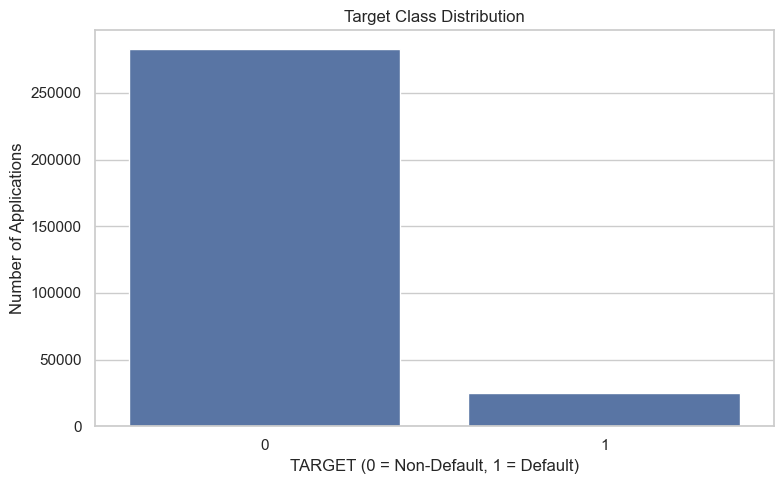

In [4]:
# STEP 4: Exploratory analysis of important application variables

numeric_eda = [
    c for c in [
        "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY",
        "AMT_GOODS_PRICE", "DAYS_BIRTH", "DAYS_EMPLOYED"
    ] if c in app.columns
]

display(app[numeric_eda].describe().T)

if "AMT_INCOME_TOTAL" in app.columns and "AMT_CREDIT" in app.columns:
    eda = app[["TARGET", "AMT_INCOME_TOTAL", "AMT_CREDIT"]].copy()
    eda["CREDIT_INCOME_RATIO"] = (
        eda["AMT_CREDIT"] / eda["AMT_INCOME_TOTAL"].replace(0, np.nan)
    )
    eda["INCOME_GROUP"] = pd.qcut(
        eda["AMT_INCOME_TOTAL"], q=5, duplicates="drop"
    )
    income_default = eda.groupby("INCOME_GROUP", observed=False)["TARGET"].agg(
        ["count", "mean"]
    )
    income_default["default_rate_percent"] = income_default["mean"] * 100
    print("Default rate across income groups:")
    display(income_default.round(4))

plt.figure(figsize=(8, 5))
sns.countplot(data=app, x="TARGET")
plt.title("Target Class Distribution")
plt.xlabel("TARGET (0 = Non-Default, 1 = Default)")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()


,CREDIT_TO_INCOME,ANNUITY_TO_INCOME,CREDIT_TO_ANNUITY
TARGET,,,
0,3.9637,0.1805,21.6868
1,3.8874,0.1855,20.7648


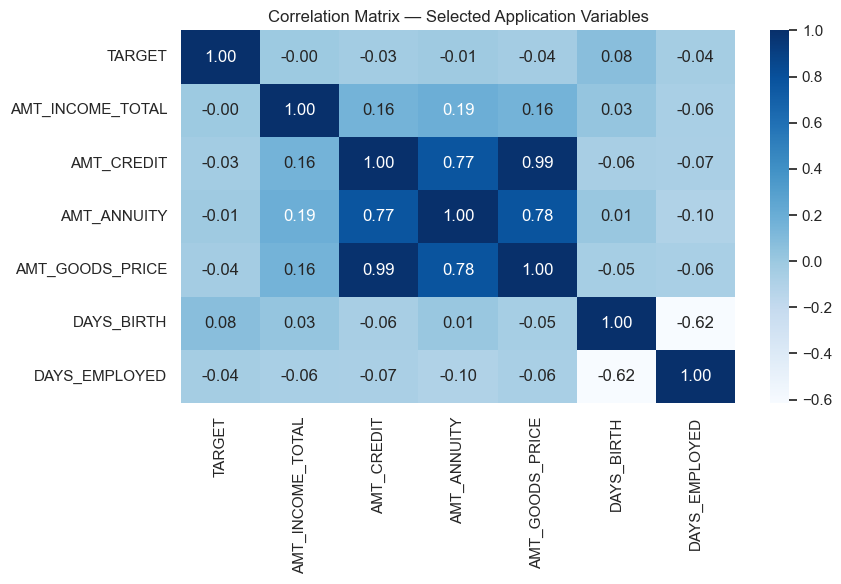

In [5]:
# STEP 5: Useful financial relationships in the base application data

ratio_columns = {}

if {"AMT_CREDIT", "AMT_INCOME_TOTAL"}.issubset(app.columns):
    ratio_columns["CREDIT_TO_INCOME"] = (
        app["AMT_CREDIT"] / app["AMT_INCOME_TOTAL"].replace(0, np.nan)
    )

if {"AMT_ANNUITY", "AMT_INCOME_TOTAL"}.issubset(app.columns):
    ratio_columns["ANNUITY_TO_INCOME"] = (
        app["AMT_ANNUITY"] / app["AMT_INCOME_TOTAL"].replace(0, np.nan)
    )

if {"AMT_CREDIT", "AMT_ANNUITY"}.issubset(app.columns):
    ratio_columns["CREDIT_TO_ANNUITY"] = (
        app["AMT_CREDIT"] / app["AMT_ANNUITY"].replace(0, np.nan)
    )

ratio_eda = pd.DataFrame(ratio_columns)
ratio_eda["TARGET"] = app["TARGET"].values

display(ratio_eda.groupby("TARGET").mean(numeric_only=True).round(4))

corr_cols = [
    c for c in [
        "TARGET", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY",
        "AMT_GOODS_PRICE", "DAYS_BIRTH", "DAYS_EMPLOYED"
    ] if c in app.columns
]

plt.figure(figsize=(9, 6))
sns.heatmap(app[corr_cols].corr(numeric_only=True), annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlation Matrix — Selected Application Variables")
plt.tight_layout()
plt.show()


## 3. Historical data feature engineering

### Why aggregation is necessary

The historical tables have different granularities:

- `bureau.csv`: previous credit-level records.
- `bureau_balance.csv`: monthly history of bureau credits.
- `previous_application.csv`: previous application-level records.
- `POS_CASH_balance.csv`: monthly POS/cash records.
- `credit_card_balance.csv`: monthly credit-card records.
- `installments_payments.csv`: individual repayment/installment records.

A raw merge would create multiple rows per current applicant. Therefore, each historical table is reduced to **one row per `SK_ID_CURR`** before merging.


In [7]:
# STEP 6: Reusable chunked aggregation helpers

def existing_columns(path):
    return pd.read_csv(path, nrows=0).columns.tolist()


def aggregate_numeric_chunks(path, numeric_cols, prefix, chunksize=CHUNK_SIZE):
    """Aggregate historical numeric variables to one row per SK_ID_CURR.

    Sum/count are combined across chunks so that derived means are weighted
    correctly. Max/min are combined directly.
    """
    path = Path(path)
    available = existing_columns(path)
    numeric_cols = [c for c in numeric_cols if c in available]

    if not numeric_cols:
        return pd.DataFrame(columns=["SK_ID_CURR"])

    usecols = ["SK_ID_CURR"] + numeric_cols
    partials = []

    for chunk in pd.read_csv(path, usecols=usecols, chunksize=chunksize):
        chunk = chunk[chunk["SK_ID_CURR"].notna()].copy()
        for col in numeric_cols:
            chunk[col] = pd.to_numeric(chunk[col], errors="coerce")

        grouped = chunk.groupby("SK_ID_CURR", sort=False)

        out = grouped.size().rename(f"{prefix}_RECORD_COUNT").to_frame()

        agg = grouped[numeric_cols].agg(["sum", "max", "min", "count"])
        agg.columns = [
            f"{prefix}_{col}_{stat.upper()}"
            for col, stat in agg.columns
        ]
        out = out.join(agg)
        partials.append(out)

        del chunk, grouped, out, agg
        gc.collect()

    partial = pd.concat(partials, axis=0)
    grouped = partial.groupby(level=0)

    final = pd.DataFrame(index=grouped.size().index)
    final[f"{prefix}_RECORD_COUNT"] = grouped[f"{prefix}_RECORD_COUNT"].sum()

    for col in numeric_cols:
        s = f"{prefix}_{col}_SUM"
        mx = f"{prefix}_{col}_MAX"
        mn = f"{prefix}_{col}_MIN"
        ct = f"{prefix}_{col}_COUNT"
        final[s] = grouped[s].sum()
        final[mx] = grouped[mx].max()
        final[mn] = grouped[mn].min()
        final[f"{prefix}_{col}_MEAN"] = (
            final[s] / final[ct].replace(0, np.nan)
        )

    final.index.name = "SK_ID_CURR"
    return final.reset_index()


def aggregate_category_counts(path, category_col, prefix, selected_values=None,
                              chunksize=CHUNK_SIZE):
    """Count selected categorical values per SK_ID_CURR in chunks."""
    path = Path(path)
    available = existing_columns(path)

    if category_col not in available:
        return pd.DataFrame(columns=["SK_ID_CURR"])

    usecols = ["SK_ID_CURR", category_col]
    partials = []

    for chunk in pd.read_csv(path, usecols=usecols, chunksize=chunksize):
        chunk = chunk[chunk["SK_ID_CURR"].notna()].copy()
        values = chunk[category_col].fillna("MISSING").astype(str)

        if selected_values is not None:
            values = values.where(values.isin(selected_values), "OTHER")

        dummies = pd.get_dummies(values, prefix=f"{prefix}_{category_col}", dtype=np.int32)
        dummies["SK_ID_CURR"] = chunk["SK_ID_CURR"].values
        grouped = dummies.groupby("SK_ID_CURR", sort=False).sum()
        partials.append(grouped)

        del chunk, values, dummies, grouped
        gc.collect()

    result = pd.concat(partials, axis=0).groupby(level=0).sum()
    result.index.name = "SK_ID_CURR"
    return result.reset_index()


In [8]:
# STEP 7: Bureau Features
# Bureau data contains previous credit information for each applicant.
# We aggregate it to SK_ID_CURR level before merging with application data.

bureau_path = PROJECT_DIR / "bureau.csv"

# Read only the required bureau columns
bureau_cols = [
    "SK_ID_CURR",
    "SK_ID_BUREAU",
    "CREDIT_ACTIVE",
    "DAYS_CREDIT",
    "CREDIT_DAY_OVERDUE",
    "AMT_CREDIT_SUM",
    "AMT_CREDIT_SUM_DEBT",
    "AMT_CREDIT_SUM_OVERDUE"
]

# Keep only columns that actually exist in the dataset
available_bureau_cols = existing_columns(bureau_path)

usecols = [
    col for col in bureau_cols
    if col in available_bureau_cols
]

bureau = pd.read_csv(
    bureau_path,
    usecols=usecols
)

# Create applicant-level bureau features
bureau_features = (
    bureau
    .groupby("SK_ID_CURR")
    .agg(
        BUREAU_CREDIT_COUNT=("SK_ID_BUREAU", "count"),
        BUREAU_ACTIVE_COUNT=(
            "CREDIT_ACTIVE",
            lambda x: (x == "Active").sum()
        ),
        BUREAU_CLOSED_COUNT=(
            "CREDIT_ACTIVE",
            lambda x: (x == "Closed").sum()
        ),
        BUREAU_DAYS_CREDIT_MEAN=(
            "DAYS_CREDIT",
            "mean"
        ),
        BUREAU_DAYS_CREDIT_MIN=(
            "DAYS_CREDIT",
            "min"
        ),
        BUREAU_DAYS_CREDIT_MAX=(
            "DAYS_CREDIT",
            "max"
        ),
        BUREAU_CREDIT_OVERDUE_MEAN=(
            "CREDIT_DAY_OVERDUE",
            "mean"
        ),
        BUREAU_CREDIT_OVERDUE_MAX=(
            "CREDIT_DAY_OVERDUE",
            "max"
        ),
        BUREAU_AMT_CREDIT_SUM_MEAN=(
            "AMT_CREDIT_SUM",
            "mean"
        ),
        BUREAU_AMT_CREDIT_SUM_TOTAL=(
            "AMT_CREDIT_SUM",
            "sum"
        ),
        BUREAU_AMT_CREDIT_DEBT_MEAN=(
            "AMT_CREDIT_SUM_DEBT",
            "mean"
        ),
        BUREAU_AMT_CREDIT_DEBT_TOTAL=(
            "AMT_CREDIT_SUM_DEBT",
            "sum"
        ),
        BUREAU_AMT_OVERDUE_MEAN=(
            "AMT_CREDIT_SUM_OVERDUE",
            "mean"
        ),
        BUREAU_AMT_OVERDUE_TOTAL=(
            "AMT_CREDIT_SUM_OVERDUE",
            "sum"
        )
    )
    .reset_index()
)

# Debt-to-credit ratio
bureau_features["BUREAU_DEBT_TO_CREDIT"] = (
    bureau_features["BUREAU_AMT_CREDIT_DEBT_TOTAL"]
    /
    bureau_features["BUREAU_AMT_CREDIT_SUM_TOTAL"]
    .replace(0, np.nan)
)

# Overdue-to-credit ratio
bureau_features["BUREAU_OVERDUE_TO_CREDIT"] = (
    bureau_features["BUREAU_AMT_OVERDUE_TOTAL"]
    /
    bureau_features["BUREAU_AMT_CREDIT_SUM_TOTAL"]
    .replace(0, np.nan)
)

# Replace infinite values
bureau_features = bureau_features.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Bureau feature shape:", bureau_features.shape)
display(bureau_features.head())

Bureau feature shape: (305811, 17)


,SK_ID_CURR,BUREAU_CREDIT_COUNT,BUREAU_ACTIVE_COUNT,BUREAU_CLOSED_COUNT,BUREAU_DAYS_CREDIT_MEAN,BUREAU_DAYS_CREDIT_MIN,BUREAU_DAYS_CREDIT_MAX,BUREAU_CREDIT_OVERDUE_MEAN,BUREAU_CREDIT_OVERDUE_MAX,BUREAU_AMT_CREDIT_SUM_MEAN,BUREAU_AMT_CREDIT_SUM_TOTAL,BUREAU_AMT_CREDIT_DEBT_MEAN,BUREAU_AMT_CREDIT_DEBT_TOTAL,BUREAU_AMT_OVERDUE_MEAN,BUREAU_AMT_OVERDUE_TOTAL,BUREAU_DEBT_TO_CREDIT,BUREAU_OVERDUE_TO_CREDIT
0,100001,7,3,4,-735.0000,-1572,-49,0.0000,0,"207,623.5714","1,453,365.0000","85,240.9286","596,686.5000",0.0000,0.0000,0.4106,0.0000
1,100002,8,2,6,-874.0000,-1437,-103,0.0000,0,"108,131.9456","865,055.5650","49,156.2000","245,781.0000",0.0000,0.0000,0.2841,0.0000
2,100003,4,1,3,"-1,400.7500",-2586,-606,0.0000,0,"254,350.1250","1,017,400.5000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,100004,2,0,2,-867.0000,-1326,-408,0.0000,0,"94,518.9000","189,037.8000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,100005,3,2,1,-190.6667,-373,-62,0.0000,0,"219,042.0000","657,126.0000","189,469.5000","568,408.5000",0.0000,0.0000,0.8650,0.0000


In [9]:
# STEP 8: Bureau balance features

# bureau_balance is linked to the current applicant through SK_ID_BUREAU.
# Only the small mapping table is loaded into memory.

bureau_map = pd.read_csv(
    bureau_path,
    usecols=["SK_ID_BUREAU", "SK_ID_CURR"]
).drop_duplicates("SK_ID_BUREAU").set_index("SK_ID_BUREAU")["SK_ID_CURR"]

def aggregate_bureau_balance(path, bureau_map, chunksize=CHUNK_SIZE):
    partials = []

    for chunk in pd.read_csv(
        path,
        usecols=["SK_ID_BUREAU", "MONTHS_BALANCE", "STATUS"],
        chunksize=chunksize
    ):
        chunk["SK_ID_CURR"] = chunk["SK_ID_BUREAU"].map(bureau_map)
        chunk = chunk[chunk["SK_ID_CURR"].notna()].copy()

        chunk["MONTHS_BALANCE"] = pd.to_numeric(
            chunk["MONTHS_BALANCE"], errors="coerce"
        )
        status = chunk["STATUS"].fillna("MISSING").astype(str)

        chunk["LATE_STATUS_FLAG"] = status.isin(["2", "3", "4", "5"]).astype(np.int8)

        grouped = chunk.groupby("SK_ID_CURR", sort=False)

        out = pd.DataFrame(index=grouped.size().index)
        out["BUREAU_BAL_RECORD_COUNT"] = grouped.size()
        out["BUREAU_BAL_MONTHS_SUM"] = grouped["MONTHS_BALANCE"].sum()
        out["BUREAU_BAL_MONTHS_COUNT"] = grouped["MONTHS_BALANCE"].count()
        out["BUREAU_BAL_LATE_COUNT"] = grouped["LATE_STATUS_FLAG"].sum()

        dummies = pd.get_dummies(
            status,
            prefix="BUREAU_BAL_STATUS",
            dtype=np.int32
        )
        dummies["SK_ID_CURR"] = chunk["SK_ID_CURR"].values
        status_counts = dummies.groupby("SK_ID_CURR").sum()
        out = out.join(status_counts)

        partials.append(out)

        del chunk, status, grouped, out, dummies, status_counts
        gc.collect()

    result = pd.concat(partials, axis=0).groupby(level=0).sum(min_count=1)
    result.index.name = "SK_ID_CURR"

    result["BUREAU_BAL_MONTHS_MEAN"] = (
        result["BUREAU_BAL_MONTHS_SUM"] /
        result["BUREAU_BAL_MONTHS_COUNT"].replace(0, np.nan)
    )

    if "BUREAU_BAL_RECORD_COUNT" in result.columns:
        result["BUREAU_BAL_LATE_RATIO"] = (
            result["BUREAU_BAL_LATE_COUNT"] /
            result["BUREAU_BAL_RECORD_COUNT"].replace(0, np.nan)
        )

    return result.reset_index()

bureau_balance_features = aggregate_bureau_balance(
    PROJECT_DIR / "bureau_balance.csv",
    bureau_map
)

print("Bureau balance feature shape:", bureau_balance_features.shape)
display(bureau_balance_features.head())


Bureau balance feature shape: (134542, 15)


,SK_ID_CURR,BUREAU_BAL_RECORD_COUNT,BUREAU_BAL_MONTHS_SUM,BUREAU_BAL_MONTHS_COUNT,BUREAU_BAL_LATE_COUNT,BUREAU_BAL_STATUS_0,BUREAU_BAL_STATUS_1,BUREAU_BAL_STATUS_2,BUREAU_BAL_STATUS_3,BUREAU_BAL_STATUS_4,BUREAU_BAL_STATUS_5,BUREAU_BAL_STATUS_C,BUREAU_BAL_STATUS_X,BUREAU_BAL_MONTHS_MEAN,BUREAU_BAL_LATE_RATIO
0,"100,001.0000",172,-2800,172,0,31,1,0,0,0,0,110,30,-16.2791,0.0000
1,"100,002.0000",110,-2701,110,0,45,27,0,0,0,0,23,15,-24.5545,0.0000
2,"100,005.0000",21,-91,21,0,14,0,0,0,0,0,5,2,-4.3333,0.0000
3,"100,010.0000",72,-3312,72,0,20,0,0,0,0,0,52,0,-46.0000,0.0000
4,"100,013.0000",230,-6756,230,0,79,7,0,0,0,0,103,41,-29.3739,0.0000


In [10]:
# STEP 9: Previous Application Features
# This step summarizes each applicant's previous loan applications.
# It captures previous application amounts, payment information,
# decision outcomes, and other historical credit behavior.

previous_path = PROJECT_DIR / "previous_application.csv"

# Columns required from previous_application.csv
previous_cols = [
    "SK_ID_CURR",
    "AMT_ANNUITY",
    "AMT_APPLICATION",
    "AMT_CREDIT",
    "AMT_DOWN_PAYMENT",
    "AMT_GOODS_PRICE",
    "DAYS_DECISION",
    "CNT_PAYMENT",
    "RATE_DOWN_PAYMENT",
    "NAME_CONTRACT_STATUS"
]

available_cols = existing_columns(previous_path)

usecols = [
    col for col in previous_cols
    if col in available_cols
]

previous = pd.read_csv(
    previous_path,
    usecols=usecols
)

# Numerical features
numeric_previous = [
    col for col in [
        "AMT_ANNUITY",
        "AMT_APPLICATION",
        "AMT_CREDIT",
        "AMT_DOWN_PAYMENT",
        "AMT_GOODS_PRICE",
        "DAYS_DECISION",
        "CNT_PAYMENT",
        "RATE_DOWN_PAYMENT"
    ]
    if col in previous.columns
]

# Convert numeric columns safely
for col in numeric_previous:
    previous[col] = pd.to_numeric(
        previous[col],
        errors="coerce"
    )

# Aggregate previous applications at applicant level
previous_features = (
    previous
    .groupby("SK_ID_CURR")
    .agg(
        **{
            f"PREV_APP_{col}_MEAN": (col, "mean")
            for col in numeric_previous
        },
        **{
            f"PREV_APP_{col}_MAX": (col, "max")
            for col in numeric_previous
        },
        **{
            f"PREV_APP_{col}_MIN": (col, "min")
            for col in numeric_previous
        },
        **{
            f"PREV_APP_{col}_SUM": (col, "sum")
            for col in numeric_previous
        }
    )
    .reset_index()
)

# Number of previous applications
application_count = (
    previous.groupby("SK_ID_CURR")
    .size()
    .reset_index(name="PREV_APP_COUNT")
)

previous_features = previous_features.merge(
    application_count,
    on="SK_ID_CURR",
    how="left"
)

# Previous application status features
if "NAME_CONTRACT_STATUS" in previous.columns:

    previous["NAME_CONTRACT_STATUS"] = (
        previous["NAME_CONTRACT_STATUS"]
        .fillna("Unknown")
        .astype(str)
    )

    status_features = (
        previous
        .groupby("SK_ID_CURR")["NAME_CONTRACT_STATUS"]
        .agg(
            PREV_APP_APPROVED_COUNT=lambda x:
                (x == "Approved").sum(),

            PREV_APP_REFUSED_COUNT=lambda x:
                (x == "Refused").sum(),

            PREV_APP_CANCELED_COUNT=lambda x:
                (x == "Canceled").sum(),

            PREV_APP_UNUSED_OFFER_COUNT=lambda x:
                (x == "Unused offer").sum()
        )
        .reset_index()
    )

    previous_features = previous_features.merge(
        status_features,
        on="SK_ID_CURR",
        how="left"
    )

# Replace infinite values
previous_features = previous_features.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Previous application feature shape:",
      previous_features.shape)

display(previous_features.head())

Previous application feature shape: (338857, 38)


,SK_ID_CURR,PREV_APP_AMT_ANNUITY_MEAN,PREV_APP_AMT_APPLICATION_MEAN,PREV_APP_AMT_CREDIT_MEAN,PREV_APP_AMT_DOWN_PAYMENT_MEAN,PREV_APP_AMT_GOODS_PRICE_MEAN,PREV_APP_DAYS_DECISION_MEAN,PREV_APP_CNT_PAYMENT_MEAN,PREV_APP_RATE_DOWN_PAYMENT_MEAN,PREV_APP_AMT_ANNUITY_MAX,PREV_APP_AMT_APPLICATION_MAX,PREV_APP_AMT_CREDIT_MAX,PREV_APP_AMT_DOWN_PAYMENT_MAX,PREV_APP_AMT_GOODS_PRICE_MAX,PREV_APP_DAYS_DECISION_MAX,PREV_APP_CNT_PAYMENT_MAX,PREV_APP_RATE_DOWN_PAYMENT_MAX,PREV_APP_AMT_ANNUITY_MIN,PREV_APP_AMT_APPLICATION_MIN,PREV_APP_AMT_CREDIT_MIN,PREV_APP_AMT_DOWN_PAYMENT_MIN,PREV_APP_AMT_GOODS_PRICE_MIN,PREV_APP_DAYS_DECISION_MIN,PREV_APP_CNT_PAYMENT_MIN,PREV_APP_RATE_DOWN_PAYMENT_MIN,PREV_APP_AMT_ANNUITY_SUM,PREV_APP_AMT_APPLICATION_SUM,PREV_APP_AMT_CREDIT_SUM,PREV_APP_AMT_DOWN_PAYMENT_SUM,PREV_APP_AMT_GOODS_PRICE_SUM,PREV_APP_DAYS_DECISION_SUM,PREV_APP_CNT_PAYMENT_SUM,PREV_APP_RATE_DOWN_PAYMENT_SUM,PREV_APP_COUNT,PREV_APP_APPROVED_COUNT,PREV_APP_REFUSED_COUNT,PREV_APP_CANCELED_COUNT,PREV_APP_UNUSED_OFFER_COUNT
0,100001,"3,951.0000","24,835.5000","23,787.0000","2,520.0000","24,835.5000","-1,740.0000",8.0000,0.1043,"3,951.0000","24,835.5000","23,787.0000","2,520.0000","24,835.5000",-1740,8.0000,0.1043,"3,951.0000","24,835.5000","23,787.0000","2,520.0000","24,835.5000",-1740,8.0000,0.1043,"3,951.0000","24,835.5000","23,787.0000","2,520.0000","24,835.5000",-1740,8.0000,0.1043,1,1,0,0,0
1,100002,"9,251.7750","179,055.0000","179,055.0000",0.0000,"179,055.0000",-606.0000,24.0000,0.0000,"9,251.7750","179,055.0000","179,055.0000",0.0000,"179,055.0000",-606,24.0000,0.0000,"9,251.7750","179,055.0000","179,055.0000",0.0000,"179,055.0000",-606,24.0000,0.0000,"9,251.7750","179,055.0000","179,055.0000",0.0000,"179,055.0000",-606,24.0000,0.0000,1,1,0,0,0
2,100003,"56,553.9900","435,436.5000","484,191.0000","3,442.5000","435,436.5000","-1,305.0000",10.0000,0.0500,"98,356.9950","900,000.0000","1,035,882.0000","6,885.0000","900,000.0000",-746,12.0000,0.1001,"6,737.3100","68,809.5000","68,053.5000",0.0000,"68,809.5000",-2341,6.0000,0.0000,"169,661.9700","1,306,309.5000","1,452,573.0000","6,885.0000","1,306,309.5000",-3915,30.0000,0.1001,3,3,0,0,0
3,100004,"5,357.2500","24,282.0000","20,106.0000","4,860.0000","24,282.0000",-815.0000,4.0000,0.2120,"5,357.2500","24,282.0000","20,106.0000","4,860.0000","24,282.0000",-815,4.0000,0.2120,"5,357.2500","24,282.0000","20,106.0000","4,860.0000","24,282.0000",-815,4.0000,0.2120,"5,357.2500","24,282.0000","20,106.0000","4,860.0000","24,282.0000",-815,4.0000,0.2120,1,1,0,0,0
4,100005,"4,813.2000","22,308.7500","20,076.7500","4,464.0000","44,617.5000",-536.0000,12.0000,0.1090,"4,813.2000","44,617.5000","40,153.5000","4,464.0000","44,617.5000",-315,12.0000,0.1090,"4,813.2000",0.0000,0.0000,"4,464.0000","44,617.5000",-757,12.0000,0.1090,"4,813.2000","44,617.5000","40,153.5000","4,464.0000","44,617.5000",-1072,12.0000,0.1090,2,1,0,1,0


In [11]:
# STEP 10: POS/CASH Balance Features
# This dataset contains historical installment and payment-status
# information for previous credit accounts.

pos_path = PROJECT_DIR / "POS_CASH_balance.csv"

pos_cols = [
    "SK_ID_CURR",
    "SK_ID_PREV",
    "MONTHS_BALANCE",
    "CNT_INSTALMENT",
    "CNT_INSTALMENT_FUTURE",
    "SK_DPD",
    "SK_DPD_DEF",
    "NAME_CONTRACT_STATUS"
]

available_cols = existing_columns(pos_path)

usecols = [
    col for col in pos_cols
    if col in available_cols
]

pos = pd.read_csv(
    pos_path,
    usecols=usecols
)

# Convert numerical columns
pos_numeric = [
    col for col in [
        "MONTHS_BALANCE",
        "CNT_INSTALMENT",
        "CNT_INSTALMENT_FUTURE",
        "SK_DPD",
        "SK_DPD_DEF"
    ]
    if col in pos.columns
]

for col in pos_numeric:
    pos[col] = pd.to_numeric(
        pos[col],
        errors="coerce"
    )

# Aggregate POS/CASH information at applicant level
pos_features = (
    pos
    .groupby("SK_ID_CURR")
    .agg(
        **{
            f"POS_{col}_MEAN": (col, "mean")
            for col in pos_numeric
        },
        **{
            f"POS_{col}_MAX": (col, "max")
            for col in pos_numeric
        },
        **{
            f"POS_{col}_MIN": (col, "min")
            for col in pos_numeric
        }
    )
    .reset_index()
)

# Number of POS/CASH records
pos_count = (
    pos.groupby("SK_ID_CURR")
    .size()
    .reset_index(name="POS_RECORD_COUNT")
)

pos_features = pos_features.merge(
    pos_count,
    on="SK_ID_CURR",
    how="left"
)

# Contract-status features
if "NAME_CONTRACT_STATUS" in pos.columns:

    pos["NAME_CONTRACT_STATUS"] = (
        pos["NAME_CONTRACT_STATUS"]
        .fillna("Unknown")
        .astype(str)
    )

    pos_status = (
        pos
        .groupby("SK_ID_CURR")["NAME_CONTRACT_STATUS"]
        .agg(
            POS_ACTIVE_COUNT=lambda x:
                (x == "Active").sum(),

            POS_COMPLETED_COUNT=lambda x:
                (x == "Completed").sum(),

            POS_SIGNED_COUNT=lambda x:
                (x == "Signed").sum(),

            POS_DEMAND_COUNT=lambda x:
                (x == "Demand").sum(),

            POS_RETURNED_COUNT=lambda x:
                (x == "Returned").sum()
        )
        .reset_index()
    )

    pos_features = pos_features.merge(
        pos_status,
        on="SK_ID_CURR",
        how="left"
    )

# Replace infinite values
pos_features = pos_features.replace(
    [np.inf, -np.inf],
    np.nan
)

print("POS/CASH feature shape:", pos_features.shape)

display(pos_features.head())

POS/CASH feature shape: (337252, 22)


,SK_ID_CURR,POS_MONTHS_BALANCE_MEAN,POS_CNT_INSTALMENT_MEAN,POS_CNT_INSTALMENT_FUTURE_MEAN,POS_SK_DPD_MEAN,POS_SK_DPD_DEF_MEAN,POS_MONTHS_BALANCE_MAX,POS_CNT_INSTALMENT_MAX,POS_CNT_INSTALMENT_FUTURE_MAX,POS_SK_DPD_MAX,POS_SK_DPD_DEF_MAX,POS_MONTHS_BALANCE_MIN,POS_CNT_INSTALMENT_MIN,POS_CNT_INSTALMENT_FUTURE_MIN,POS_SK_DPD_MIN,POS_SK_DPD_DEF_MIN,POS_RECORD_COUNT,POS_ACTIVE_COUNT,POS_COMPLETED_COUNT,POS_SIGNED_COUNT,POS_DEMAND_COUNT,POS_RETURNED_COUNT
0,100001,-72.5556,4.0000,1.4444,0.7778,0.7778,-53,4.0000,4.0000,7,7,-96,4.0000,0.0000,0,0,9,7,2,0,0,0
1,100002,-10.0000,24.0000,15.0000,0.0000,0.0000,-1,24.0000,24.0000,0,0,-19,24.0000,6.0000,0,0,19,19,0,0,0,0
2,100003,-43.7857,10.1071,5.7857,0.0000,0.0000,-18,12.0000,12.0000,0,0,-77,6.0000,0.0000,0,0,28,26,2,0,0,0
3,100004,-25.5000,3.7500,2.2500,0.0000,0.0000,-24,4.0000,4.0000,0,0,-27,3.0000,0.0000,0,0,4,3,1,0,0,0
4,100005,-20.0000,11.7000,7.2000,0.0000,0.0000,-15,12.0000,12.0000,0,0,-25,9.0000,0.0000,0,0,11,9,1,1,0,0


In [12]:
# STEP 11: Credit Card Balance Features

cc_path = PROJECT_DIR / "credit_card_balance.csv"

# Required columns from the Credit Card Balance dataset
cc_cols = [
    "SK_ID_CURR",
    "SK_ID_PREV",
    "MONTHS_BALANCE",
    "AMT_BALANCE",
    "AMT_CREDIT_LIMIT_ACTUAL",
    "AMT_DRAWINGS_ATM_CURRENT",
    "AMT_DRAWINGS_CURRENT",
    "AMT_PAYMENT_CURRENT",
    "AMT_PAYMENT_TOTAL_CURRENT",
    "AMT_RECEIVABLE_PRINCIPAL",
    "CNT_DRAWINGS_CURRENT",
    "SK_DPD",
    "SK_DPD_DEF"
]

# Read only columns that actually exist
available_cols = existing_columns(cc_path)

usecols = [
    col for col in cc_cols
    if col in available_cols
]

cc = pd.read_csv(
    cc_path,
    usecols=usecols
)

# Numeric columns
cc_numeric = [
    col for col in [
        "MONTHS_BALANCE",
        "AMT_BALANCE",
        "AMT_CREDIT_LIMIT_ACTUAL",
        "AMT_DRAWINGS_ATM_CURRENT",
        "AMT_DRAWINGS_CURRENT",
        "AMT_PAYMENT_CURRENT",
        "AMT_PAYMENT_TOTAL_CURRENT",
        "AMT_RECEIVABLE_PRINCIPAL",
        "CNT_DRAWINGS_CURRENT",
        "SK_DPD",
        "SK_DPD_DEF"
    ]
    if col in cc.columns
]

# Convert to numeric
for col in cc_numeric:
    cc[col] = pd.to_numeric(
        cc[col],
        errors="coerce"
    )

# Aggregate credit-card behaviour at applicant level
cc_agg = (
    cc.groupby("SK_ID_CURR")[cc_numeric]
    .agg(["mean", "max", "min"])
)

# Flatten multi-level column names
cc_agg.columns = [
    f"CC_{col}_{stat.upper()}"
    for col, stat in cc_agg.columns
]

cc_features = cc_agg.reset_index()

# Number of credit-card records
cc_count = (
    cc.groupby("SK_ID_CURR")
    .size()
    .reset_index(name="CC_RECORD_COUNT")
)

cc_features = cc_features.merge(
    cc_count,
    on="SK_ID_CURR",
    how="left"
)

# Replace infinite values
cc_features = cc_features.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Credit-card feature shape:", cc_features.shape)

display(cc_features.head())

Credit-card feature shape: (103558, 35)


,SK_ID_CURR,CC_MONTHS_BALANCE_MEAN,CC_MONTHS_BALANCE_MAX,CC_MONTHS_BALANCE_MIN,CC_AMT_BALANCE_MEAN,CC_AMT_BALANCE_MAX,CC_AMT_BALANCE_MIN,CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN,CC_AMT_CREDIT_LIMIT_ACTUAL_MAX,CC_AMT_CREDIT_LIMIT_ACTUAL_MIN,CC_AMT_DRAWINGS_ATM_CURRENT_MEAN,CC_AMT_DRAWINGS_ATM_CURRENT_MAX,CC_AMT_DRAWINGS_ATM_CURRENT_MIN,CC_AMT_DRAWINGS_CURRENT_MEAN,CC_AMT_DRAWINGS_CURRENT_MAX,CC_AMT_DRAWINGS_CURRENT_MIN,CC_AMT_PAYMENT_CURRENT_MEAN,CC_AMT_PAYMENT_CURRENT_MAX,CC_AMT_PAYMENT_CURRENT_MIN,CC_AMT_PAYMENT_TOTAL_CURRENT_MEAN,CC_AMT_PAYMENT_TOTAL_CURRENT_MAX,CC_AMT_PAYMENT_TOTAL_CURRENT_MIN,CC_AMT_RECEIVABLE_PRINCIPAL_MEAN,CC_AMT_RECEIVABLE_PRINCIPAL_MAX,CC_AMT_RECEIVABLE_PRINCIPAL_MIN,CC_CNT_DRAWINGS_CURRENT_MEAN,CC_CNT_DRAWINGS_CURRENT_MAX,CC_CNT_DRAWINGS_CURRENT_MIN,CC_SK_DPD_MEAN,CC_SK_DPD_MAX,CC_SK_DPD_MIN,CC_SK_DPD_DEF_MEAN,CC_SK_DPD_DEF_MAX,CC_SK_DPD_DEF_MIN,CC_RECORD_COUNT
0,100006,-3.5000,-1,-6,0.0000,0.0000,0.0000,"270,000.0000",270000,270000,NaN,NaN,NaN,0.0000,0.0000,0.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0,0,0.0000,0,0,0.0000,0,0,6
1,100011,-38.5000,-2,-75,"54,482.1111","189,000.0000",0.0000,"164,189.1892",180000,90000,"2,432.4324","180,000.0000",0.0000,"2,432.4324","180,000.0000",0.0000,"4,843.0642","55,485.0000",0.0000,"4,520.0676","55,485.0000",0.0000,"52,402.0889","180,000.0000",0.0000,0.0541,4,0,0.0000,0,0,0.0000,0,0,74
2,100013,-48.5000,-1,-96,"18,159.9192","161,420.2200",0.0000,"131,718.7500",157500,45000,"6,350.0000","157,500.0000",0.0000,"5,953.1250","157,500.0000",0.0000,"7,168.3462","153,675.0000",0.0000,"6,817.1723","153,675.0000",0.0000,"17,255.5598","157,500.0000",0.0000,0.2396,7,0,0.0104,1,0,0.0104,1,0,96
3,100021,-10.0000,-2,-18,0.0000,0.0000,0.0000,"675,000.0000",675000,675000,NaN,NaN,NaN,0.0000,0.0000,0.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0,0,0.0000,0,0,0.0000,0,0,17
4,100023,-7.5000,-4,-11,0.0000,0.0000,0.0000,"135,000.0000",225000,45000,NaN,NaN,NaN,0.0000,0.0000,0.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0,0,0.0000,0,0,0.0000,0,0,8


In [13]:
# STEP 12: Installment payment behaviour features

installments_path = PROJECT_DIR / "installments_payments.csv"

def aggregate_installments(path, chunksize=CHUNK_SIZE):
    partials = []

    usecols = [
        "SK_ID_CURR", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER",
        "DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT",
        "AMT_INSTALMENT", "AMT_PAYMENT"
    ]

    for chunk in pd.read_csv(path, usecols=usecols, chunksize=chunksize):
        chunk = chunk[chunk["SK_ID_CURR"].notna()].copy()

        for col in usecols[1:]:
            chunk[col] = pd.to_numeric(chunk[col], errors="coerce")

        chunk["PAYMENT_DELAY_DAYS"] = (
            chunk["DAYS_ENTRY_PAYMENT"] - chunk["DAYS_INSTALMENT"]
        )

        chunk["PAYMENT_SHORTFALL"] = (
            chunk["AMT_INSTALMENT"] - chunk["AMT_PAYMENT"]
        )

        chunk["LATE_PAYMENT_FLAG"] = (
            chunk["PAYMENT_DELAY_DAYS"] > 0
        ).astype(np.int8)

        grouped = chunk.groupby("SK_ID_CURR", sort=False)

        numeric = [
            "PAYMENT_DELAY_DAYS",
            "PAYMENT_SHORTFALL",
            "AMT_INSTALMENT",
            "AMT_PAYMENT",
            "NUM_INSTALMENT_VERSION"
        ]

        out = grouped.size().rename("INST_RECORD_COUNT").to_frame()
        agg = grouped[numeric].agg(["sum", "max", "min", "count"])
        agg.columns = [
            f"INST_{col}_{stat.upper()}"
            for col, stat in agg.columns
        ]
        out = out.join(agg)
        out["INST_LATE_PAYMENT_COUNT"] = grouped["LATE_PAYMENT_FLAG"].sum()

        partials.append(out)

        del chunk, grouped, out, agg
        gc.collect()

    partial = pd.concat(partials, axis=0)
    grouped = partial.groupby(level=0)

    result = pd.DataFrame(index=grouped.size().index)
    result["INST_RECORD_COUNT"] = grouped["INST_RECORD_COUNT"].sum()
    result["INST_LATE_PAYMENT_COUNT"] = grouped["INST_LATE_PAYMENT_COUNT"].sum()

    for col in [
        "PAYMENT_DELAY_DAYS", "PAYMENT_SHORTFALL",
        "AMT_INSTALMENT", "AMT_PAYMENT", "NUM_INSTALMENT_VERSION"
    ]:
        s = f"INST_{col}_SUM"
        mx = f"INST_{col}_MAX"
        mn = f"INST_{col}_MIN"
        ct = f"INST_{col}_COUNT"

        result[s] = grouped[s].sum()
        result[mx] = grouped[mx].max()
        result[mn] = grouped[mn].min()
        result[f"INST_{col}_MEAN"] = (
            result[s] / grouped[ct].sum().replace(0, np.nan)
        )

    result["INST_LATE_PAYMENT_RATIO"] = (
        result["INST_LATE_PAYMENT_COUNT"] /
        result["INST_RECORD_COUNT"].replace(0, np.nan)
    )

    result.index.name = "SK_ID_CURR"
    return result.reset_index()

installment_features = aggregate_installments(installments_path)

print("Installment feature shape:", installment_features.shape)
display(installment_features.head())


Installment feature shape: (339587, 24)


,SK_ID_CURR,INST_RECORD_COUNT,INST_LATE_PAYMENT_COUNT,INST_PAYMENT_DELAY_DAYS_SUM,INST_PAYMENT_DELAY_DAYS_MAX,INST_PAYMENT_DELAY_DAYS_MIN,INST_PAYMENT_DELAY_DAYS_MEAN,INST_PAYMENT_SHORTFALL_SUM,INST_PAYMENT_SHORTFALL_MAX,INST_PAYMENT_SHORTFALL_MIN,INST_PAYMENT_SHORTFALL_MEAN,INST_AMT_INSTALMENT_SUM,INST_AMT_INSTALMENT_MAX,INST_AMT_INSTALMENT_MIN,INST_AMT_INSTALMENT_MEAN,INST_AMT_PAYMENT_SUM,INST_AMT_PAYMENT_MAX,INST_AMT_PAYMENT_MIN,INST_AMT_PAYMENT_MEAN,INST_NUM_INSTALMENT_VERSION_SUM,INST_NUM_INSTALMENT_VERSION_MAX,INST_NUM_INSTALMENT_VERSION_MIN,INST_NUM_INSTALMENT_VERSION_MEAN,INST_LATE_PAYMENT_RATIO
0,100001,7,1,-51.0000,11.0000,-36.0000,-7.2857,0.0000,0.0000,0.0000,0.0000,"41,195.9250","17,397.9000","3,951.0000","5,885.1321","41,195.9250","17,397.9000","3,951.0000","5,885.1321",8.0000,2.0000,1.0000,1.1429,0.1429
1,100002,19,0,-388.0000,-12.0000,-31.0000,-20.4211,0.0000,0.0000,0.0000,0.0000,"219,625.6950","53,093.7450","9,251.7750","11,559.2471","219,625.6950","53,093.7450","9,251.7750","11,559.2471",20.0000,2.0000,1.0000,1.0526,0.0000
2,100003,25,0,-179.0000,-1.0000,-14.0000,-7.1600,0.0000,0.0000,0.0000,0.0000,"1,618,864.6500","560,835.3600","6,662.9700","64,754.5860","1,618,864.6500","560,835.3600","6,662.9700","64,754.5860",26.0000,2.0000,1.0000,1.0400,0.0000
3,100004,3,0,-23.0000,-3.0000,-11.0000,-7.6667,0.0000,0.0000,0.0000,0.0000,"21,288.4650","10,573.9650","5,357.2500","7,096.1550","21,288.4650","10,573.9650","5,357.2500","7,096.1550",4.0000,2.0000,1.0000,1.3333,0.0000
4,100005,9,1,-212.0000,1.0000,-37.0000,-23.5556,0.0000,0.0000,0.0000,0.0000,"56,161.8450","17,656.2450","4,813.2000","6,240.2050","56,161.8450","17,656.2450","4,813.2000","6,240.2050",10.0000,2.0000,1.0000,1.1111,0.1111


In [14]:
# STEP 13: Add useful derived ratios to credit-card features

if not cc_features.empty:
    balance_mean = "CC_AMT_BALANCE_MEAN"
    limit_mean = "CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN"
    payment_mean = "CC_AMT_PAYMENT_TOTAL_CURRENT_MEAN"

    if {balance_mean, limit_mean}.issubset(cc_features.columns):
        cc_features["CC_UTILIZATION_MEAN"] = (
            cc_features[balance_mean] /
            cc_features[limit_mean].replace(0, np.nan)
        )

    if {payment_mean, balance_mean}.issubset(cc_features.columns):
        cc_features["CC_PAYMENT_TO_BALANCE_MEAN"] = (
            cc_features[payment_mean] /
            cc_features[balance_mean].replace(0, np.nan)
        )

display(cc_features.head())


,SK_ID_CURR,CC_MONTHS_BALANCE_MEAN,CC_MONTHS_BALANCE_MAX,CC_MONTHS_BALANCE_MIN,CC_AMT_BALANCE_MEAN,CC_AMT_BALANCE_MAX,CC_AMT_BALANCE_MIN,CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN,CC_AMT_CREDIT_LIMIT_ACTUAL_MAX,CC_AMT_CREDIT_LIMIT_ACTUAL_MIN,CC_AMT_DRAWINGS_ATM_CURRENT_MEAN,CC_AMT_DRAWINGS_ATM_CURRENT_MAX,CC_AMT_DRAWINGS_ATM_CURRENT_MIN,CC_AMT_DRAWINGS_CURRENT_MEAN,CC_AMT_DRAWINGS_CURRENT_MAX,CC_AMT_DRAWINGS_CURRENT_MIN,CC_AMT_PAYMENT_CURRENT_MEAN,CC_AMT_PAYMENT_CURRENT_MAX,CC_AMT_PAYMENT_CURRENT_MIN,CC_AMT_PAYMENT_TOTAL_CURRENT_MEAN,CC_AMT_PAYMENT_TOTAL_CURRENT_MAX,CC_AMT_PAYMENT_TOTAL_CURRENT_MIN,CC_AMT_RECEIVABLE_PRINCIPAL_MEAN,CC_AMT_RECEIVABLE_PRINCIPAL_MAX,CC_AMT_RECEIVABLE_PRINCIPAL_MIN,CC_CNT_DRAWINGS_CURRENT_MEAN,CC_CNT_DRAWINGS_CURRENT_MAX,CC_CNT_DRAWINGS_CURRENT_MIN,CC_SK_DPD_MEAN,CC_SK_DPD_MAX,CC_SK_DPD_MIN,CC_SK_DPD_DEF_MEAN,CC_SK_DPD_DEF_MAX,CC_SK_DPD_DEF_MIN,CC_RECORD_COUNT,CC_UTILIZATION_MEAN,CC_PAYMENT_TO_BALANCE_MEAN
0,100006,-3.5000,-1,-6,0.0000,0.0000,0.0000,"270,000.0000",270000,270000,NaN,NaN,NaN,0.0000,0.0000,0.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0,0,0.0000,0,0,0.0000,0,0,6,0.0000,NaN
1,100011,-38.5000,-2,-75,"54,482.1111","189,000.0000",0.0000,"164,189.1892",180000,90000,"2,432.4324","180,000.0000",0.0000,"2,432.4324","180,000.0000",0.0000,"4,843.0642","55,485.0000",0.0000,"4,520.0676","55,485.0000",0.0000,"52,402.0889","180,000.0000",0.0000,0.0541,4,0,0.0000,0,0,0.0000,0,0,74,0.3318,0.0830
2,100013,-48.5000,-1,-96,"18,159.9192","161,420.2200",0.0000,"131,718.7500",157500,45000,"6,350.0000","157,500.0000",0.0000,"5,953.1250","157,500.0000",0.0000,"7,168.3462","153,675.0000",0.0000,"6,817.1723","153,675.0000",0.0000,"17,255.5598","157,500.0000",0.0000,0.2396,7,0,0.0104,1,0,0.0104,1,0,96,0.1379,0.3754
3,100021,-10.0000,-2,-18,0.0000,0.0000,0.0000,"675,000.0000",675000,675000,NaN,NaN,NaN,0.0000,0.0000,0.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0,0,0.0000,0,0,0.0000,0,0,17,0.0000,NaN
4,100023,-7.5000,-4,-11,0.0000,0.0000,0.0000,"135,000.0000",225000,45000,NaN,NaN,NaN,0.0000,0.0000,0.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0,0,0.0000,0,0,0.0000,0,0,8,0.0000,NaN


## 4. Build the final applicant-level modelling dataset

All six historical sources are now represented through engineered features keyed by `SK_ID_CURR`.

This is the critical integration step: the target remains from `application_train.csv`, while historical behaviour is added without duplicating current applications.


In [15]:
# STEP 14: Merge all seven datasets at applicant level

model_df = app.copy()

historical_feature_tables = [
    bureau_features,
    bureau_balance_features,
    previous_features,
    pos_features,
    cc_features,
    installment_features
]

for features in historical_feature_tables:
    model_df = model_df.merge(
        features,
        on="SK_ID_CURR",
        how="left"
    )

    del features
    gc.collect()

print("Final enriched modelling dataset shape:", model_df.shape)

historical_columns = [
    c for c in model_df.columns
    if c.startswith(("BUREAU_", "PREV_APP_", "POS_", "CC_", "INST_"))
]

print("Number of engineered historical features:", len(historical_columns))
print("\nSample historical features:")
display(pd.DataFrame({"Feature": historical_columns[:40]}))


Final enriched modelling dataset shape: (307511, 269)
Number of engineered historical features: 147

Sample historical features:


,Feature
0,BUREAU_CREDIT_COUNT
1,BUREAU_ACTIVE_COUNT
2,BUREAU_CLOSED_COUNT
3,BUREAU_DAYS_CREDIT_MEAN
4,BUREAU_DAYS_CREDIT_MIN
5,BUREAU_DAYS_CREDIT_MAX
6,BUREAU_CREDIT_OVERDUE_MEAN
7,BUREAU_CREDIT_OVERDUE_MAX
8,BUREAU_AMT_CREDIT_SUM_MEAN
9,BUREAU_AMT_CREDIT_SUM_TOTAL


In [35]:
# STEP 15: Verify that historical features are actually populated

coverage = []

for prefix in [
    "BUREAU_",
    "BUREAU_BAL_",
    "PREV_APP_",
    "POS_",
    "CC_",
    "INST_"
]:
    cols = [c for c in model_df.columns if c.startswith(prefix)]
    if cols:
        non_missing_rows = model_df[cols].notna().any(axis=1).mean()
        coverage.append({
            "Historical Source": prefix.rstrip("_"),
            "Feature Count": len(cols),
            "Applicants With At Least One Feature": round(non_missing_rows * 100, 2)
        })

coverage_df = pd.DataFrame(coverage)
display(coverage_df)

print("Duplicate SK_ID_CURR values after integration:", model_df["SK_ID_CURR"].duplicated().sum())


,Historical Source,Feature Count,Applicants With At Least One Feature
0,BUREAU,30,85.6900
1,BUREAU_BAL,14,29.9900
2,PREV_APP,37,94.6500
3,POS,21,94.1200
4,CC,36,28.2600
5,INST,23,94.8400


Duplicate SK_ID_CURR values after integration: 0


## 5. Prepare data for modelling

The modelling pipeline handles missing values and categorical variables without leaking information from the test set.

Columns with extremely high missingness are removed from the modelling matrix. The target and applicant ID are excluded from predictors.


In [17]:
# STEP 16: Remove extremely sparse columns and separate X/y

missing_rate = model_df.isnull().mean()
high_missing_columns = missing_rate[missing_rate > 0.80].index.tolist()

# Never remove the target or ID through this rule.
high_missing_columns = [
    c for c in high_missing_columns
    if c not in ["TARGET", "SK_ID_CURR"]
]

print("Columns removed because missingness > 80%:", len(high_missing_columns))

model_df_reduced = model_df.drop(columns=high_missing_columns).copy()

X = model_df_reduced.drop(columns=["TARGET", "SK_ID_CURR"])
y = model_df_reduced["TARGET"].astype(int)
applicant_ids = model_df_reduced["SK_ID_CURR"]

print("Predictor shape:", X.shape)
print("Target distribution:")
display(y.value_counts(normalize=True).rename("Proportion").to_frame())


Columns removed because missingness > 80%: 7
Predictor shape: (307511, 260)
Target distribution:


,Proportion
TARGET,
0,0.9193
1,0.0807


In [18]:
# STEP 17: Stratified train/validation/test split

# 70% training, 15% validation, 15% final test.
# The validation set is used for model selection and threshold analysis.
# The final test set remains untouched until the final evaluation.

X_train_temp, X_test, y_train_temp, y_test, id_train_temp, id_test = train_test_split(
    X, y, applicant_ids,
    test_size=0.15,
    stratify=y,
    random_state=RANDOM_STATE
)

X_train, X_val, y_train, y_val, id_train, id_val = train_test_split(
    X_train_temp, y_train_temp, id_train_temp,
    test_size=0.17647,  # approximately 15% of the full dataset
    stratify=y_train_temp,
    random_state=RANDOM_STATE
)

print("Training rows   :", len(X_train))
print("Validation rows :", len(X_val))
print("Test rows       :", len(X_test))

print("\nDefault rate by split:")
print("Train      :", round(y_train.mean(), 4))
print("Validation :", round(y_val.mean(), 4))
print("Test       :", round(y_test.mean(), 4))


Training rows   : 215257
Validation rows : 46127
Test rows       : 46127

Default rate by split:
Train      : 0.0807
Validation : 0.0807
Test       : 0.0807


In [19]:
# STEP 18: Build preprocessing pipeline

numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number", "bool"]).columns.tolist()

try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=True)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler(with_mean=False))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop",
    sparse_threshold=1.0
)

print("Numeric features    :", len(numeric_features))
print("Categorical features:", len(categorical_features))


Numeric features    : 244
Categorical features: 16


## 6. Train and compare multiple classification models

Two different classification approaches are used:

- **Logistic Regression** — interpretable linear baseline.
- **Random Forest** — nonlinear ensemble model capable of capturing interactions.

Because default cases are the minority class, **PR-AUC (Average Precision)** is included alongside ROC-AUC, precision, recall, F1-score and accuracy.


In [25]:
# STEP 19: Define candidate models

logistic_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        solver="liblinear",
        random_state=RANDOM_STATE
    ))
])

random_forest_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}


In [22]:
# STEP 20: Train candidates and compare validation performance

validation_results = []
fitted_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)

    probability = model.predict_proba(X_val)[:, 1]
    prediction = (probability >= 0.50).astype(int)

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, prediction),
        "Precision": precision_score(y_val, prediction, zero_division=0),
        "Recall": recall_score(y_val, prediction, zero_division=0),
        "F1-Score": f1_score(y_val, prediction, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probability),
        "PR-AUC": average_precision_score(y_val, probability)
    })

    fitted_models[name] = model

comparison = pd.DataFrame(validation_results).sort_values(
    by=["PR-AUC", "ROC-AUC"],
    ascending=False
).reset_index(drop=True)

print("Validation Model Comparison")
display(comparison.round(4))


Training Logistic Regression...
Training Random Forest...
Validation Model Comparison


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.7061,0.1731,0.6990,0.2775,0.7728,0.2534
1,Random Forest,0.8100,0.2081,0.4823,0.2907,0.7503,0.2251


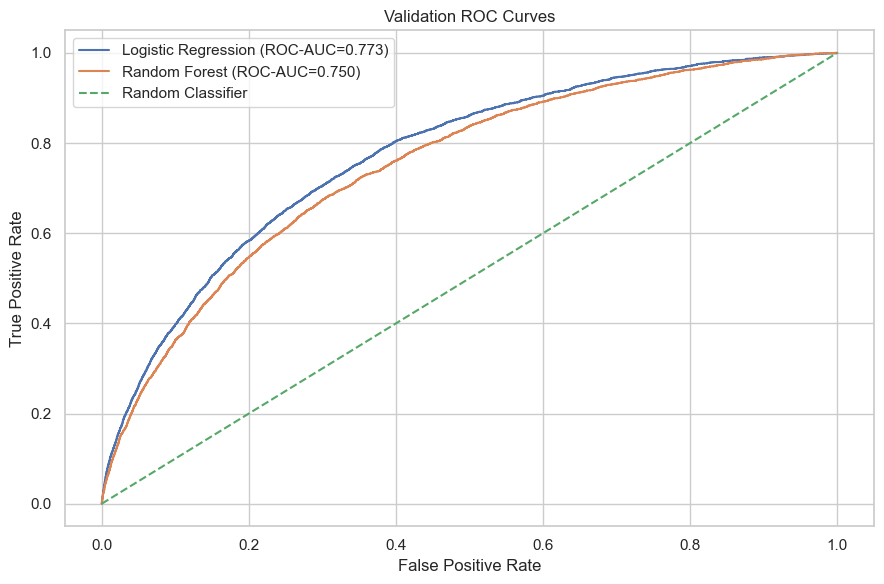

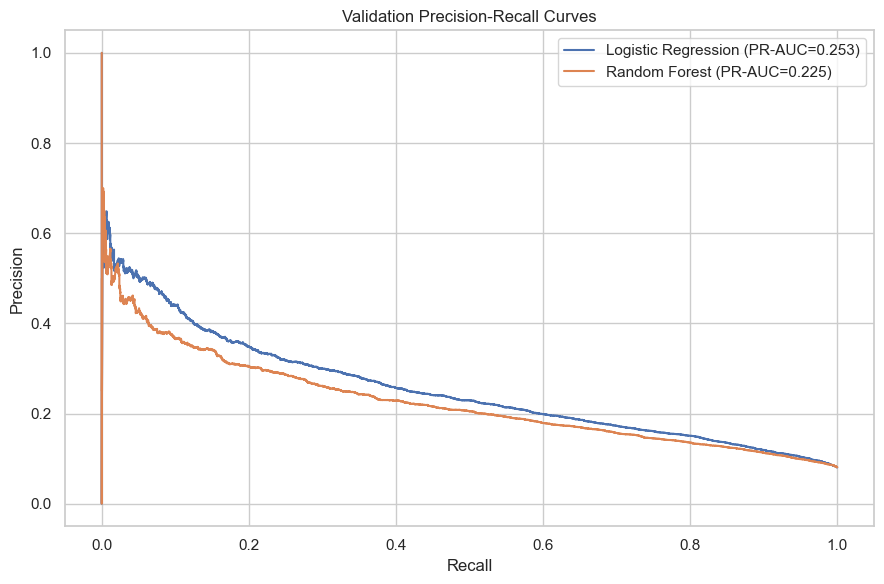

In [26]:
# STEP 21: ROC and Precision-Recall curves for both candidates

plt.figure(figsize=(9, 6))

for name, model in fitted_models.items():
    prob = model.predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, prob)
    auc_value = roc_auc_score(y_val, prob)
    plt.plot(fpr, tpr, label=f"{name} (ROC-AUC={auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))

for name, model in fitted_models.items():
    prob = model.predict_proba(X_val)[:, 1]
    precision, recall, _ = precision_recall_curve(y_val, prob)
    ap = average_precision_score(y_val, prob)
    plt.plot(recall, precision, label=f"{name} (PR-AUC={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation Precision-Recall Curves")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Select the production candidate using measured validation performance

For this imbalanced default-risk problem, PR-AUC is used as the primary comparison metric because it focuses on the positive/default class. ROC-AUC is retained as a secondary discrimination metric.

The code below selects the candidate with the strongest measured validation PR-AUC, using ROC-AUC as the tie-breaker. This avoids hard-coding a model choice before the new all-dataset model results are produced.


In [27]:
# STEP 22: Select candidate model from validation results

selected_model_name = comparison.iloc[0]["Model"]
selected_validation_model = fitted_models[selected_model_name]

print("Selected candidate based on validation PR-AUC:", selected_model_name)
print("Validation PR-AUC:", round(
    comparison.loc[comparison["Model"] == selected_model_name, "PR-AUC"].iloc[0], 4
))
print("Validation ROC-AUC:", round(
    comparison.loc[comparison["Model"] == selected_model_name, "ROC-AUC"].iloc[0], 4
))


Selected candidate based on validation PR-AUC: Logistic Regression
Validation PR-AUC: 0.2534
Validation ROC-AUC: 0.7728


## 8. Classification-threshold analysis

A probability threshold of 0.50 is only a default convention. For credit-risk applications, changing the threshold changes the precision-recall balance.

The threshold is selected **using validation data only**. The final test set is not used to select the threshold.


In [28]:
# STEP 23: Evaluate thresholds on validation data

val_probability = selected_validation_model.predict_proba(X_val)[:, 1]

threshold_values = np.arange(0.10, 0.91, 0.05)
threshold_rows = []

for threshold in threshold_values:
    pred = (val_probability >= threshold).astype(int)

    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1-Score": f1_score(y_val, pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)

# F1 is used here as a transparent threshold-selection criterion.
best_threshold = float(
    threshold_df.loc[threshold_df["F1-Score"].idxmax(), "Threshold"]
)

display(threshold_df.round(4))
print("Selected validation threshold:", best_threshold)


,Threshold,Precision,Recall,F1-Score
0,0.1000,0.0845,0.9949,0.1558
1,0.1500,0.0901,0.9842,0.1651
2,0.2000,0.0976,0.9664,0.1773
3,0.2500,0.1069,0.9409,0.1920
4,0.3000,0.1172,0.9049,0.2075
5,0.3500,0.1296,0.8684,0.2256
6,0.4000,0.1431,0.8233,0.2438
7,0.4500,0.1567,0.7666,0.2603
8,0.5000,0.1731,0.6990,0.2775
9,0.5500,0.1912,0.6318,0.2936


Selected validation threshold: 0.6500000000000001


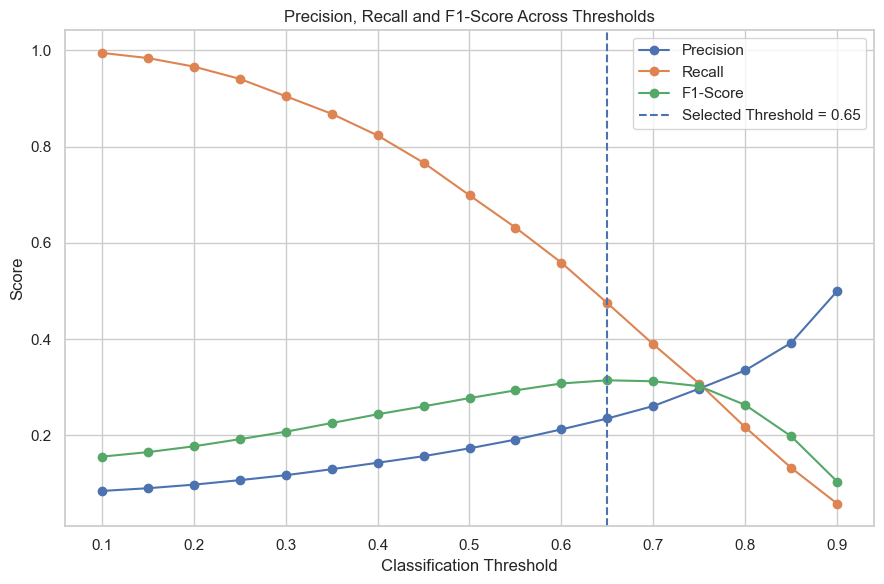

In [29]:
# STEP 24: Visualize the threshold trade-off

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Selected Threshold = {best_threshold:.2f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1-Score Across Thresholds")
plt.legend()
plt.tight_layout()
plt.show()


## 9. Final model fitting and untouched test-set evaluation

After selecting the model and threshold on the training/validation data, the selected model is refit using the combined training + validation data.

The final test set is then used once for the final performance report.


In [30]:
# STEP 25: Refit selected model on training + validation data

X_train_full = pd.concat([X_train, X_val], axis=0)
y_train_full = pd.concat([y_train, y_val], axis=0)

final_model = clone(models[selected_model_name])
final_model.fit(X_train_full, y_train_full)

test_probability = final_model.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= best_threshold).astype(int)

final_metrics = {
    "Accuracy": accuracy_score(y_test, test_prediction),
    "Precision": precision_score(y_test, test_prediction, zero_division=0),
    "Recall": recall_score(y_test, test_prediction, zero_division=0),
    "F1-Score": f1_score(y_test, test_prediction, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probability),
    "PR-AUC": average_precision_score(y_test, test_probability)
}

final_metrics_df = pd.DataFrame(
    final_metrics.items(),
    columns=["Metric", "Value"]
)

display(final_metrics_df.round(4))


,Metric,Value
0,Accuracy,0.8370
1,Precision,0.2439
2,Recall,0.4850
3,F1-Score,0.3245
4,ROC-AUC,0.7738
5,PR-AUC,0.2586


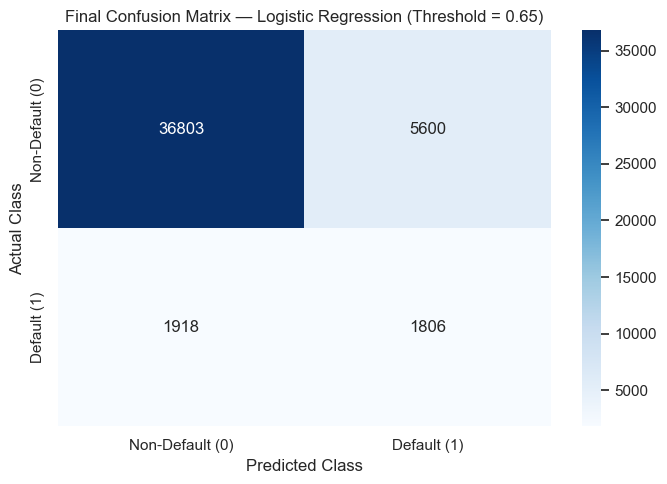

Final Classification Report
                 precision    recall  f1-score   support

Non-Default (0)     0.9505    0.8679    0.9073     42403
    Default (1)     0.2439    0.4850    0.3245      3724

       accuracy                         0.8370     46127
      macro avg     0.5972    0.6764    0.6159     46127
   weighted avg     0.8934    0.8370    0.8603     46127



In [31]:
# STEP 26: Final confusion matrix and classification report

final_cm = confusion_matrix(y_test, test_prediction)

plt.figure(figsize=(7, 5))
sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Default (0)", "Default (1)"],
    yticklabels=["Non-Default (0)", "Default (1)"]
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title(
    f"Final Confusion Matrix — {selected_model_name} "
    f"(Threshold = {best_threshold:.2f})"
)
plt.tight_layout()
plt.show()

print("Final Classification Report")
print(
    classification_report(
        y_test,
        test_prediction,
        target_names=["Non-Default (0)", "Default (1)"],
        digits=4
    )
)


## 10. Feature importance / important risk factors

Feature importance is used to identify variables associated with the model's predictions.

**Important:** feature importance describes predictive contribution; it does not establish that a feature causes loan default.


Top 20 predictive features:


,Feature,Importance
0,cat__ORGANIZATION_TYPE_XNA,6.2175
1,num__DAYS_EMPLOYED,5.6362
2,cat__NAME_INCOME_TYPE_Pensioner,4.1318
3,num__INST_AMT_PAYMENT_SUM,3.4830
4,num__INST_AMT_INSTALMENT_SUM,3.3699
5,cat__NAME_INCOME_TYPE_Working,2.3612
6,cat__NAME_INCOME_TYPE_Commercial associate,2.2959
7,cat__NAME_INCOME_TYPE_State servant,2.2432
8,cat__NAME_INCOME_TYPE_Unemployed,2.1037
9,num__CC_MONTHS_BALANCE_MIN,1.5474


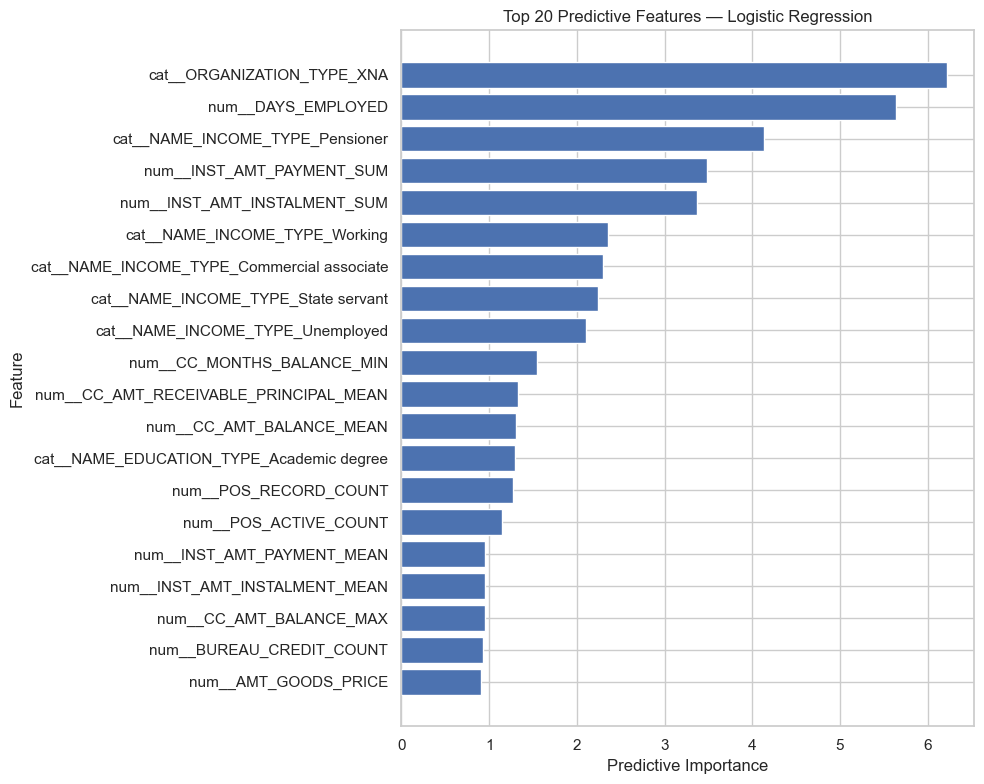

In [32]:
# STEP 27: Extract model feature importance / coefficients

preprocess_final = final_model.named_steps["preprocess"]
classifier_final = final_model.named_steps["model"]

feature_names = preprocess_final.get_feature_names_out()

if hasattr(classifier_final, "feature_importances_"):
    importance_values = classifier_final.feature_importances_
    importance_table = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance_values
    }).sort_values("Importance", ascending=False)
else:
    coefficient_values = np.abs(classifier_final.coef_[0])
    importance_table = pd.DataFrame({
        "Feature": feature_names,
        "Importance": coefficient_values
    }).sort_values("Importance", ascending=False)

importance_table = importance_table.reset_index(drop=True)

print("Top 20 predictive features:")
display(importance_table.head(20).round(4))

top20 = importance_table.head(20).sort_values("Importance", ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(top20["Feature"], top20["Importance"])
plt.xlabel("Predictive Importance")
plt.ylabel("Feature")
plt.title(f"Top 20 Predictive Features — {selected_model_name}")
plt.tight_layout()
plt.show()


## 11. Customer / risk segmentation

The institute asks for factors/customer segments relevant to loan eligibility/risk assessment.

Because the target is default, the segmentation below is framed as **predicted default-risk segments**, not an automatic loan-approval decision.

- Low risk: predicted default probability below 20%.
- Medium risk: 20% to below 50%.
- High risk: 50% or above.

These bands are descriptive and can be changed by a financial institution based on its risk policy.


In [33]:
# STEP 28: Applicant-level predicted risk segments

segment_df = pd.DataFrame({
    "SK_ID_CURR": id_test.values,
    "Predicted_Default_Probability": test_probability,
    "Actual_TARGET": y_test.values
})

segment_df["Risk_Segment"] = pd.cut(
    segment_df["Predicted_Default_Probability"],
    bins=[-np.inf, 0.20, 0.50, np.inf],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

segment_summary = (
    segment_df.groupby("Risk_Segment", observed=False)
    .agg(
        Applicants=("SK_ID_CURR", "count"),
        Average_Predicted_Risk=("Predicted_Default_Probability", "mean"),
        Observed_Default_Rate=("Actual_TARGET", "mean")
    )
)

segment_summary["Observed_Default_Rate"] *= 100
segment_summary["Average_Predicted_Risk"] *= 100

display(segment_summary.round(2))


,Applicants,Average_Predicted_Risk,Observed_Default_Rate
Risk_Segment,,,
Low Risk,9354,13.2900,1.3900
Medium Risk,21816,34.1400,4.5800
High Risk,14957,66.6700,17.3500


## Business Interpretation

The enriched dataset combines current application information with historical credit and repayment behaviour. This allows the model to consider more than static applicant characteristics.

The risk segments can support a workflow in which applications are prioritised for different levels of review. A higher predicted default probability indicates higher model-estimated risk, but it should not be treated as an automatic rejection rule.

Historical features such as previous credit activity, previous application outcomes, repayment delays, POS/cash behaviour and credit-card utilisation provide additional context for credit-risk assessment.

The feature-importance analysis should be interpreted as a description of predictive association rather than causation.


## 12. Model limitations and considerations

- **Class imbalance:** Default cases are less frequent than non-default cases, so accuracy alone is insufficient.
- **Historical-data coverage:** Not every applicant has records in every historical table. Missing historical records may represent absence of observed history rather than a conventional missing-value problem.
- **Threshold dependency:** Changing the probability threshold changes precision, recall and F1-score.
- **Feature importance is not causality:** A highly important variable does not prove that changing that variable causes default risk to change.
- **Generalisation:** Performance should be checked on newer and representative applicant populations before deployment.
- **Monitoring:** Applicant behaviour, economic conditions and lending policies can change over time; model performance should therefore be monitored.
- **Fairness and governance:** Real lending deployment requires appropriate regulatory, fairness, explainability, privacy and governance checks.
- **Decision support:** Predictions should support credit-risk assessment and human review rather than automatically determine lending outcomes.


## 13. Challenges faced, techniques used and reasons

### Challenge 1 — Different dataset granularities
**Technique:** Aggregate every historical table to `SK_ID_CURR` before merging.

**Reason:** Directly joining monthly and previous-credit tables would duplicate current application rows and could distort the model.

### Challenge 2 — Very large historical files
**Technique:** Chunked CSV processing with `chunksize`.

**Reason:** The historical tables can contain millions of records. Processing chunks reduces peak memory usage.

### Challenge 3 — Missing values
**Technique:** Median imputation for numerical variables and most-frequent imputation plus one-hot encoding for categorical variables.

**Reason:** This retains useful observations while allowing the machine-learning models to receive complete predictor matrices.

### Challenge 4 — Class imbalance
**Technique:** Class-weighted Logistic Regression and Random Forest, together with ROC-AUC and PR-AUC evaluation.

**Reason:** Accuracy can look acceptable while the minority default class is poorly detected.

### Challenge 5 — Categorical variables
**Technique:** One-hot encoding with `handle_unknown="ignore"`.

**Reason:** It converts categorical information into model-compatible numerical features and handles categories that appear only in validation/test data.

### Challenge 6 — Threshold selection
**Technique:** Evaluate multiple probability thresholds on the validation set and select the threshold using F1-score.

**Reason:** The threshold controls the precision-recall trade-off and should be selected without using the final test set.

### Challenge 7 — Model selection without test leakage
**Technique:** Separate training, validation and final test data.

**Reason:** The validation set is used for model and threshold selection, while the final test set remains untouched until final evaluation.


## 14. Production recommendation

The notebook selects the production candidate using the **measured validation PR-AUC**, with validation ROC-AUC as the tie-breaker.

This approach is appropriate for this imbalanced classification problem because PR-AUC focuses on the model's performance for the default class.

Before any real-world deployment, the selected model should additionally be assessed for calibration, stability, fairness, explainability, business cost of false positives/false negatives, monitoring requirements and regulatory compliance.


In [34]:
# STEP 29: Final project summary

print("FINAL PROJECT SUMMARY")
print("=" * 70)
print("Datasets integrated           :", len(REQUIRED_FILES))
print("Final modelling rows          :", len(model_df_reduced))
print("Historical features created   :", len(historical_columns))
print("Selected model                :", selected_model_name)
print("Selected threshold            :", round(best_threshold, 4))
print("Final test ROC-AUC            :", round(final_metrics["ROC-AUC"], 4))
print("Final test PR-AUC             :", round(final_metrics["PR-AUC"], 4))
print("Final test Accuracy           :", round(final_metrics["Accuracy"], 4))
print("Final test Precision          :", round(final_metrics["Precision"], 4))
print("Final test Recall             :", round(final_metrics["Recall"], 4))
print("Final test F1-Score           :", round(final_metrics["F1-Score"], 4))


FINAL PROJECT SUMMARY
Datasets integrated           : 7
Final modelling rows          : 307511
Historical features created   : 147
Selected model                : Logistic Regression
Selected threshold            : 0.65
Final test ROC-AUC            : 0.7738
Final test PR-AUC             : 0.2586
Final test Accuracy           : 0.837
Final test Precision          : 0.2439
Final test Recall             : 0.485
Final test F1-Score           : 0.3245


## Conclusion

This project developed a machine-learning-based Home Loan Default Risk Management workflow using the institute-provided application and historical datasets.

The current application information was enriched with applicant-level features derived from bureau records, bureau monthly balances, previous applications, POS/cash history, credit-card history and installment-payment behaviour.

Logistic Regression and Random Forest were evaluated using multiple classification metrics. Validation performance was used to select the candidate model and classification threshold, while the final test set was reserved for unbiased final evaluation.

The feature-importance and risk-segmentation analyses provide additional information about predictive factors and applicant-level risk groups.

The final model is intended as a **decision-support and risk-assessment tool**, not as the sole basis for lending decisions. Real-world deployment would require further validation, monitoring, governance and fairness assessment.


## Future scope

1. Hyperparameter tuning and additional algorithms such as gradient boosting can be evaluated.
2. Calibration can be added so predicted probabilities better represent observed risk.
3. SHAP or permutation importance can improve explainability.
4. Thresholds can be optimised using the financial cost of false positives and false negatives.
5. Model drift and population stability can be monitored after deployment.
6. Newer lending data can be used for temporal validation.
7. Fairness and regulatory checks can be incorporated into the production workflow.
